<a href="https://colab.research.google.com/github/Jayadeep19/pytorch/blob/master/pytorch/basics/Autograd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Pytorch Autograd (torch.atograd)

- Autograd is an important feature that helps us to train models easily.
- It is an automatic differentiation engine.
- In NN's the network learns by adjusting its parameters wrt to the error the network is making while predicting. Check my blog on back propagation for more details [back propagation](https://jayadeep19.github.io/til-notes/back-propagation)

In [6]:
import torch
import torchvision
import numpy as np

- In the example below, we can see that the `requires_grad = True` has to be passed while initilizing the tensor, to tell pytorch that we intend to calculate gradients for that particular tensor.
- And the `y.backward()` defines the point where the gradients are computed by traversing the graph
- The gradients of a function `y` wrt to the parameter `x` is stored in the `x.grad` attribute of the tensor `x`.

In [2]:
# Initilize a tensor with a scaler float for our simple experession
x = torch.tensor(3.0, requires_grad = True)

# Let us take a simple math expression and try Autograd
y = x**2

# Now we can calculate the grad manually such as:
'''
dy/dx = 2*x
'''
manual_grad = 2*x

# and auto calculation using pytorch
y.backward()

print(f"manual gradient is: ", manual_grad)
print(f"auto gradient is: ", x.grad)


manual gradient is:  tensor(6., grad_fn=<MulBackward0>)
auto gradient is:  tensor(6.)


In [3]:
# For a vector function:
x = torch.tensor([1.0,2.0,3.0], requires_grad=True)

# expression
y = x.pow(2).mean()

#calculate the gradient:
'''
manually: dy/dx = 2x/n => 2[1.0,2.0,3.0]/3 = [0.6667, 1.3333, 2.0000]
'''
y.backward()

print(f"The gradient of y wrt to x is: ", x.grad)

The gradient of y wrt to x is:  tensor([0.6667, 1.3333, 2.0000])


- Gradients get <mark>accumulated</mark> automatically, meaning:
  - for $y = x^2$ for $x = 2.0$
  - `y.backward()` - calculates $2x$
  - `y.backward()` again- calculates $8$

  - To prevent this we have to clear the gradients between the backward passes: `x.grad.zero_()`

In [4]:
x = torch.tensor(2.0, requires_grad = True)
y = x**2

y.backward(retain_graph=True)    #(4.0)
print(f'grad for 1st pass: ', x.grad)

y.backward(retain_graph=True)  #(2(4.0) = (8.0))
print(f'grad for 2nd pass: ', x.grad)

#reset the graph:
x.grad.zero_()

y.backward()  #(4.0)
print(f'grad for 3rd pass: ', x.grad)

grad for 1st pass:  tensor(4.)
grad for 2nd pass:  tensor(8.)
grad for 3rd pass:  tensor(4.)


### Finding the minimum of a parabola

- Let us experiment with a small example.
- We will take a parabola, and try to find the lowest (minimum) point in its function.
- We can do it two ways,
  1. we can just derviate the function and equate it to zero to get the minimum value
  2. we can use gradient descent with autograde to find the lowest point gradually.

Text(0, 0.5, 'y -->')

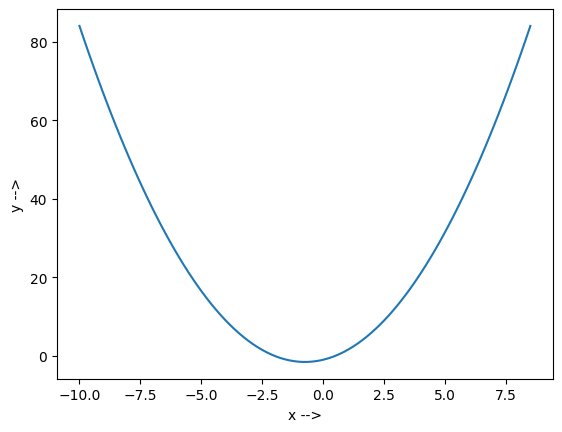

In [14]:
import matplotlib.pyplot as plt

# parabola function:
def fx(x):
  return x**2 + 1.5*x -1

# Define the x axis points
x = np.linspace(-10, 8.5, 100)

plt.plot(x, fx(x))
plt.xlabel('x -->')
plt.ylabel('y -->')



- when we create a random x axis point and find the `.backward()` we will get the slop of the curve at that point.
- So using that as starting point we can move our x value to roght or left in the direction of the negative gradient.

In [56]:
# start initilizing variables, x, learning rate, loggers for x,y, counter, dy_dx_..

#we start our descent from x = 2.5. we start from a random x-value and reach the same steep value
x_ = torch.tensor(2.5)
x_.requires_grad = True

#logger
x_log = []
y_log = []

#learning rate
lr = 0.01

#counter
counter = 0

#dy_dx_ a higher value- once becomes small enough we will stop the descent
dy_dx_ = 1000

max_steps = 1000

# start the descent:
while np.abs(dy_dx_) > 0.001:   #approximatly 0
  x_log.append(x_.item())
  #get the y value fr our x
  y_ = fx(x_)
  y_log.append(y_.item())

  #calculate the gradient
  y_.backward()
  dy_dx_ = x_.grad.item()    #gives the gradient value

  # Now that we got the gradient at that point, we can update the x_ value to right or left.
  # This update doesnot have to be tracked by pytorch for gradient calculation.
  # we can use a loop under `torch.no_grad()`
  with torch.no_grad():
    x_ -= lr*dy_dx_


    # Now that we moved the x-value to either right or left, we can reset the gradient value
    # else, pytorch will accumulate the gradient value (see above blocks)
    x_.grad.zero_()

  #update the counter and write a condition to break if max no of steps achieved
  counter +=1

  if counter == max_steps:
    break

# `x_.item()  gives the value of x iteself`
print(f'The lowest value of y: {y_.item():.2f} is achieved at {x_.item():.2f} after {counter} steps')


tensor(2.5000)
The lowest value of y: -1.56 is achieved at -0.75 after 436 steps


In [58]:
print(x_log[0])
print(y_log[0])

2.5
9.0


(-2.0, 10.0)

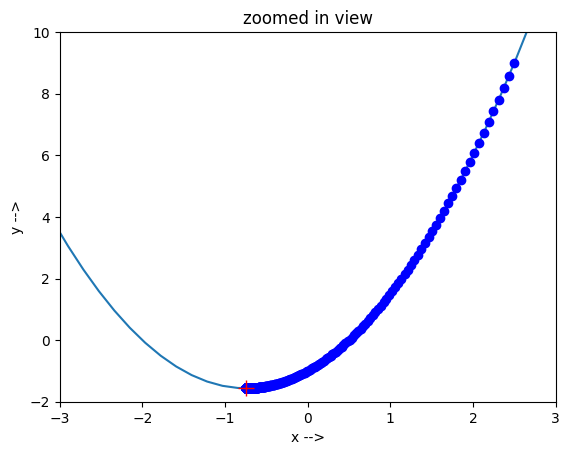

In [61]:
plt.plot(x,fx(x))
#plot the found point in the above step
for i in range(len(x_log)-1):
  plt.plot(x_log[i], y_log[i], 'bo')
plt.plot(x_.item(), y_.item(), 'r+', markersize = 12)
plt.xlabel('x -->')
plt.ylabel('y -->')
plt.title('zoomed in view')

plt.xlim(-3, 3)
plt.ylim(-2, 10)
